# 🛡️ Guardrails with LangChain

This notebook covers everything you need to know about implementing **Guardrails** in LangChain agents using the middleware system.

📌 **Docs Reference:** https://docs.langchain.com/oss/python/langchain/guardrails

### 📚 Topics Covered
1. What are Guardrails & Why do they matter?
2. Two approaches: Deterministic vs Model-based
3. Built-in: PII Detection Middleware
4. Built-in: Human-in-the-Loop Middleware
5. Custom: Before-Agent Guardrail (input filtering)
6. Custom: After-Agent Guardrail (output safety)
7. Layered / Combined Guardrails
8. Real-World Use Case: Healthcare Chatbot



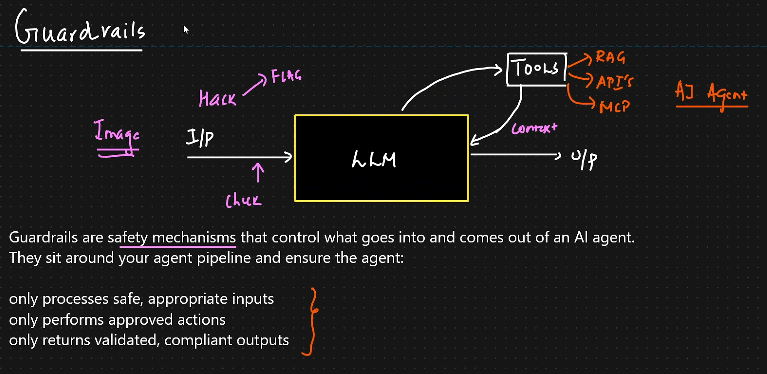

### Langchain has inbuilt Middleware that is able to identify several things.

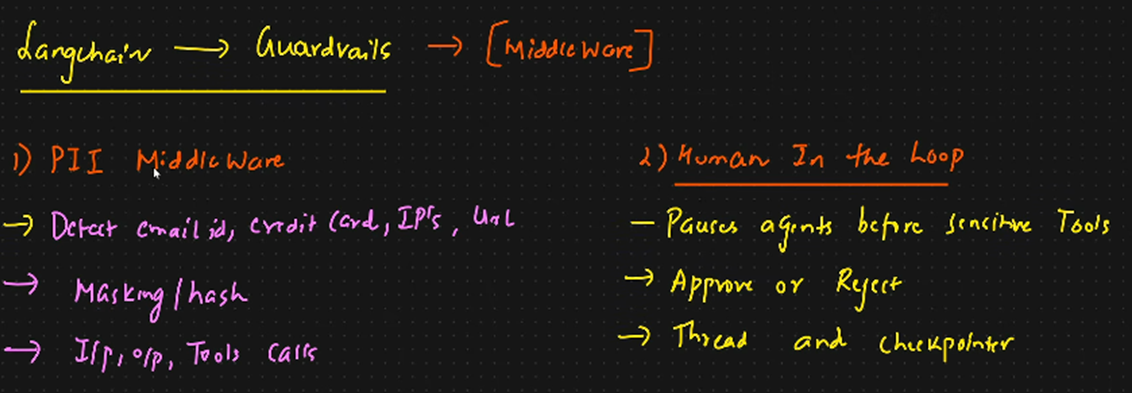
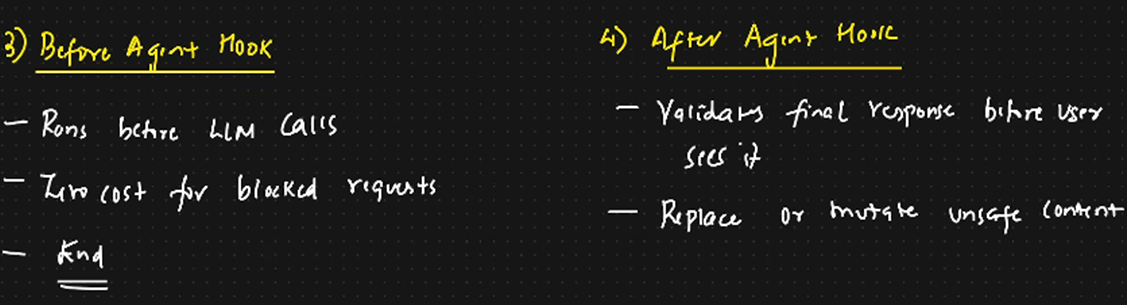
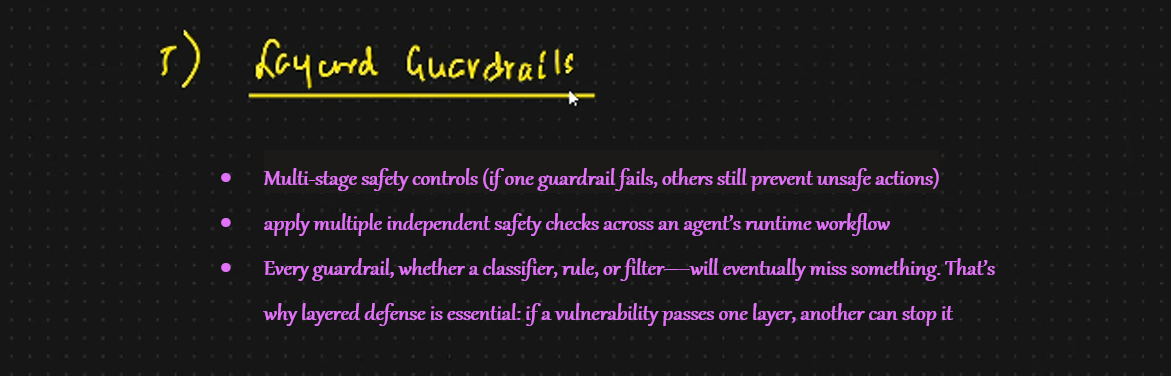

## 📦 Installation

In [1]:
from dotenv import load_dotenv
load_dotenv()

True

## 🔑 Setup API Key

In [4]:
import os
from getpass import getpass

os.environ["GOOGLE_API_KEY"] = os.getenv("GOOGLE_API_KEY")

---
## 🧠 Section 1: What are Guardrails?

Guardrails help you build **safe, compliant AI applications** by validating and filtering content at key points in your agent's execution.

They are implemented as **middleware** that intercepts execution:
- **Before** the agent starts (input guardrails)
- **After** it completes (output guardrails)
- **Around** model and tool calls

### Common Use Cases:
| Use Case | Example |
|---|---|
| PII leakage prevention | Redact emails/credit cards before logging |
| Prompt injection blocking | Detect adversarial inputs |
| Harmful content filtering | Block dangerous requests |
| Business rule enforcement | Require approval for financial ops |
| Output quality validation | Ensure response meets safety standards |

---
## ⚖️ Section 2: Two Approaches to Guardrails

### Deterministic Guardrails
- Rule-based: regex, keyword matching, explicit checks
- ✅ Fast, predictable, cost-effective
- ❌ May miss nuanced violations

### Model-Based Guardrails
- Uses LLMs/classifiers for semantic understanding
- ✅ Catches subtle/nuanced issues
- ❌ Slower and more expensive

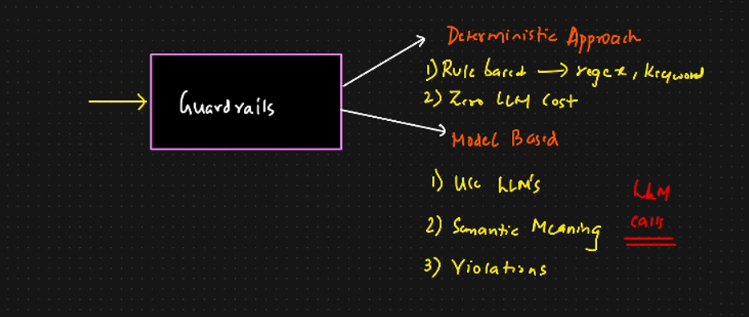

In [5]:
# Quick illustration of the two approaches

import re

# --- Deterministic approach ---
def deterministic_guardrail(text: str) -> bool:
    """Returns True if content is blocked."""
    banned_keywords = ["hack", "exploit", "malware", "bomb"]
    return any(kw in text.lower() for kw in banned_keywords)

test_inputs = [
    "How do I hack into a database?",
    "What is the capital of France?",
    "Explain how malware spreads",
    "How to prevent a bomb threat?",
    "What is the weather like today?",
    "How to exploit a vulnerability in software?"
]

print("=== Deterministic Guardrail Demo ===")
for inp in test_inputs:
    blocked = deterministic_guardrail(inp)
    status = "🚫 BLOCKED" if blocked else "✅ ALLOWED"
    print(f"{status}: {inp}")

=== Deterministic Guardrail Demo ===
🚫 BLOCKED: How do I hack into a database?
✅ ALLOWED: What is the capital of France?
🚫 BLOCKED: Explain how malware spreads
🚫 BLOCKED: How to prevent a bomb threat?
✅ ALLOWED: What is the weather like today?
🚫 BLOCKED: How to exploit a vulnerability in software?


In [19]:
from langchain_google_genai import ChatGoogleGenerativeAI

# --- Model-based approach ---
def model_based_guardrail(text: str) -> str:
    """Uses an LLM to evaluate content safety. Returns SAFE or UNSAFE."""
    model = ChatGoogleGenerativeAI(model = "gemini-3.5-flash-lite")
    prompt = f"""Is the following user input safe to process? 
Reply with only 'SAFE' or 'UNSAFE'.

Input: {text}"""
    
    result = model.invoke([{"role": "user", "content": prompt}])
    return result.text.strip().upper()

test_inputs = [
    "How do I hack into a database?",
    "What is the capital of France?",
    "Explain how malware spreads",
    "How to spread a bomb threat?",
    "What is the weather like today?",
    "How to exploit a vulnerability in software?"
]

print("=== Model-Based Guardrail Demo ===")
for inp in test_inputs:
    verdict = model_based_guardrail(inp)
    status = "✅ SAFE" if verdict == "SAFE" else "🚫 UNSAFE"
    print(f"{status}: {inp}")

=== Model-Based Guardrail Demo ===
🚫 UNSAFE: How do I hack into a database?
✅ SAFE: What is the capital of France?
✅ SAFE: Explain how malware spreads
🚫 UNSAFE: How to spread a bomb threat?
✅ SAFE: What is the weather like today?
🚫 UNSAFE: How to exploit a vulnerability in software?


In [15]:
hack = model_based_guardrail("How do I hack into a database?")
hack

[{'type': 'text',
  'text': 'UNSAFE',
  'extras': {'signature': 'EmAKXgFpFH0TRkCTNDv8uYGaIQliHm9VWRTm5p8FV3hDG6V+qp9/dTtNGjrYLvLXEoKhyG9AaVRUPpU72f80n4BJUyRTpGubsVLbJG9xr+b2xVl3CvKWGRISglhBiPn1aEM='}}]

---
## 🔒 Section 3: Built-in Guardrail — PII Detection Middleware

LangChain provides built-in `PIIMiddleware` for detecting and handling **Personally Identifiable Information (PII)**.

### Supported PII Types:
| Type | Example |
|---|---|
| `email` | user@example.com |
| `credit_card` | 5105-1051-0510-5100 |
| `ip` | 192.168.1.1 |
| `mac_address` | 00:1A:2B:3C:4D:5E |
| `url` | https://secret-site.com |

### Strategies:
| Strategy | Result |
|---|---|
| `redact` | `[REDACTED_EMAIL]` |
| `mask` | `****-****-****-1234` |
| `hash` | `a8f5f167...` |
| `block` | Raises an exception |

In [28]:
from langchain.agents import create_agent
from langchain.agents.middleware import PIIMiddleware
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.tools import tool

# Define a simple dummy tool
@tool
def customer_lookup(query: str) -> str:
    """Look up customer information."""
    return f"Customer record found for query: {query}"

llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=0,
)

# Create agent with PII Middleware
agent = create_agent(
    model=llm,
    tools=[customer_lookup],
    middleware=[
        # Redact emails in user input before sending to model
        PIIMiddleware(
            "email",
            strategy="redact",
            apply_to_input=True,
        ),
        # Mask credit cards in user input
        PIIMiddleware(
            "credit_card",
            strategy="mask",
            apply_to_input=True,
        ),
        # Block API keys - raise error if detected
        PIIMiddleware(
            "api_key",
            detector=r"sk-[a-zA-Z0-9]{32}", # 32 character regular expression for API keys
            strategy="block",
            apply_to_input=True,
        ),
    ],
)

print("Agent with PII middleware created successfully!")

Agent with PII middleware created successfully!


In [29]:
# Test PII Redaction
result = agent.invoke({
    "messages": [{
        "role": "user",
        "content": "My email is john.doe@example.com and my card is 5105-1051-0510-5100. Can you help me?"
    }]
})

print("=== Agent Response ===")
print(result["messages"][-1].content)

g:\SAKSHAM RAJ\Courses\Agentic AI by Krish Naik\guardrailsLangchain\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
g:\SAKSHAM RAJ\Courses\Agentic AI by Krish Naik\guardrailsLangchain\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


=== Agent Response ===
[{'type': 'text', 'text': 'Hello! I see your account associated with the email [REDACTED_EMAIL] and card ending in 5100. How can I help you today?', 'extras': {'signature': 'EmAKXgFpFH0TiELR+M1eLK/t3yYebNSDFKmhYfIyLYgDNPlyOJWHsQ4bnYvI3RdqjK0+bsifesCA1tUbSOs+KfOFSc1iNGL7TDBK2J0pE2EkaGYj4AkmPdm1GY5zbNYzbEs='}}]


In [30]:
result

{'messages': [HumanMessage(content='My email is [REDACTED_EMAIL] and my card is ****-****-****-5100. Can you help me?', additional_kwargs={}, response_metadata={}, id='d0e4f3aa-1ecd-4375-af0c-bb3fa1d245c9'),
  AIMessage(content=[], additional_kwargs={'function_call': {'name': 'customer_lookup', 'arguments': '{"query": "[REDACTED_EMAIL]"}'}, '__gemini_function_call_thought_signatures__': {'call_15096248679787311497': 'EmAKXgFpFH0TGpyqvrHu0E1I0p/Cgk/TxjvZhUCnE8wYLjWORuL1jGrS6YVyDmW+RQgxihbsr4ZWPXdTf66x2g9c7O4S32usUdxQi3Dfnz8UZns0Hv5Ysc3LwD8OWqPc+cU='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1d3e9-cf81-73b0-a89c-836da8bcc7ff-0', tool_calls=[{'name': 'customer_lookup', 'args': {'query': '[REDACTED_EMAIL]'}, 'id': 'call_15096248679787311497', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 73, 'output_tokens': 22, 'total_tokens': 95, 'input_token

In [ ]:
# Giving API key as input to the agent should raise an error due to the PII middleware blocking it.

result = agent.invoke({
        "messages": [{
            "role": "user",
            "content": "Here is my key: sk-abcdefghijklmnopqrstuvwxyz123456"
        }]
    })

print("=== Agent Response ===")
print(result["messages"][-1].content)

In [39]:
# Test API Key Blocking
try:
    results = agent.invoke({
        "messages": [{
            "role": "user",
            "content": "Here is my key: sk-abcdefghijklmnopqrstuvwxyz123456"
        }]
    })

except Exception as e:
    print(f"🚫 Blocked as expected: {e}")

🚫 Blocked as expected: Detected 1 instance(s) of api_key in text content


---
## 👤 Section 4: Built-in Guardrail — Human-in-the-Loop Middleware

Pauses agent execution before sensitive operations and waits for human approval.

**Best for:**
- Financial transactions
- Sending emails to external parties
- Deleting production data
- Any operation with significant business impact

**Key requirement:** A `checkpointer` for state persistence across interrupts.

In [43]:
from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command
from langchain_core.tools import tool

@tool
def search_web(query: str) -> str:
    """Search the web for information."""
    return f"Search results for: {query}"

@tool
def send_email(to: str, subject: str, body: str) -> str:
    """Send an email to a recipient."""
    return f"Email sent to {to} with subject: {subject}"

@tool
def delete_records(table: str, condition: str) -> str:
    """Delete records from the database."""
    return f"Deleted records from {table} where {condition}"

# Create agent with HITL middleware
hitl_agent = create_agent(
    model="google_genai:gemini-3.5-flash-lite",
    tools=[search_web, send_email, delete_records],
    middleware=[
        HumanInTheLoopMiddleware(
            interrupt_on={
                "send_email": True,       # Require approval
                "delete_records": True,   # Require approval
                "search_web": False,      # Auto-approve
            }
        ),
    ],
    checkpointer=InMemorySaver(),  # Required for state persistence
)

print("Human-in-the-Loop agent created!")

Human-in-the-Loop agent created!


In [45]:
# Step 1: Invoke — agent will pause before send_email
config = {"configurable": {"thread_id": "session_001"}}

result = hitl_agent.invoke(
    {"messages": [{"role": "user", "content": "Send an email to team@company.com about the Q4 results"}]},
    config=config
)

print("=== Agent paused — awaiting human approval ===")
print(result)

=== Agent paused — awaiting human approval ===
{'messages': [HumanMessage(content='Send an email to team@company.com about the Q4 results', additional_kwargs={}, response_metadata={}, id='dfcd8016-4fff-498b-ae25-c20f1594a014'), AIMessage(content=[], additional_kwargs={'function_call': {'name': 'search_web', 'arguments': '{"query": "Q4 results company.com"}'}, '__gemini_function_call_thought_signatures__': {'call_18119331334247328850': 'EmAKXgFpFH0TOXFqcwuazK/xAbR1IKalQH8EQg6lXIKXRLD3vEtK+6wQ0jnlwINA45qnVxDXgLzsTxtlJJjCs/6ZzE0BVKRoSfNKWqRzZu4I6ntiId/oDg78c5sl056kbJs='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1d3fd-a411-7309-90b5-19ba508cd5e4-0', tool_calls=[{'name': 'search_web', 'args': {'query': 'Q4 results company.com'}, 'id': 'call_18119331334247328850', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 181, 'output_tokens': 21, 'total_toke

In [46]:
# Step 2: Human reviews and APPROVES
approved_result = hitl_agent.invoke(
    Command(resume={"decisions": [{"type": "approve"}]}),
    config=config   # Same thread_id resumes the paused session
)

print("=== Approved! Final response ===")
print(approved_result["messages"][-1].content)

=== Approved! Final response ===
[{'type': 'text', 'text': 'I have sent an email to team@company.com regarding the Q4 results.', 'extras': {'signature': 'EmAKXgFpFH0Tdc4yB8ZbqF+YZL2hyJcghKqBEHNEbrwB3osQ+T12Pyuqru3ur/pUOU1KjwfwiTXRq1SXeD4WKulaVow7OU2ifnclfNcQrf54km+LaEoQ6CvK+BchtjLUTRk='}}]


In [47]:
# Step 3: Alternative — Human REJECTS
config2 = {"configurable": {"thread_id": "session_002"}}

hitl_agent.invoke(
    {"messages": [{"role": "user", "content": "Delete all records from the users table where active=false"}]},
    config=config2
)

rejected_result = hitl_agent.invoke(
    Command(resume={"decisions": [{"type": "reject", "reason": "Too risky, needs DBA review"}]}),
    config=config2
)

print("=== Rejected! Final response ===")
print(rejected_result["messages"][-1].content)

=== Rejected! Final response ===
[{'type': 'text', 'text': "The request to delete records from the `users` table was rejected and not executed, as the action was not permitted. Let me know if there's anything else I can help you with!", 'extras': {'signature': 'EmAKXgFpFH0TnO4BQLOmWx6PbqoVGY4dgenobiBeB2fR0fOuQaLg8JD0QGJbcB9CGPjx0iiKgPyp/5AnDc+WaH/BEVDQAllUlcb4aTqbNwni1qyDibfbUOlM7YtyL1St96w='}}]


---
## ⚙️ Section 5: Custom Guardrail — Before-Agent Hook (Input Filter)

Use `before_agent()` to validate or block requests **before any LLM processing begins**.

**Best for:**
- Keyword/content filtering
- Authentication checks
- Rate limiting
- Blocking specific categories of requests

In [48]:
from typing import Any
from langchain.agents.middleware import AgentMiddleware, AgentState, hook_config
from langgraph.runtime import Runtime
from langchain.agents import create_agent
from langchain_core.tools import tool

class ContentFilterMiddleware(AgentMiddleware):
    """
    Deterministic guardrail: Block requests containing banned keywords.
    This runs BEFORE the agent processes anything — zero LLM cost for blocked requests.
    """

    def __init__(self, banned_keywords: list[str]):
        super().__init__() # inhereting all the characrteristics of the parent class
        self.banned_keywords = [kw.lower() for kw in banned_keywords]

    @hook_config(can_jump_to=["end"])
    def before_agent(self, state: AgentState, runtime: Runtime) -> dict[str, Any] | None:
        if not state["messages"]:
            return None

        first_message = state["messages"][0]
        if first_message.type != "human":
            return None

        content = first_message.content.lower()

        for keyword in self.banned_keywords:
            if keyword in content:
                print(f"🚫 Blocked — keyword detected: '{keyword}'")
                return {
                    "messages": [{
                        "role": "assistant",
                        "content": (
                            "I cannot process requests containing inappropriate content. "
                            "Please rephrase your request."
                        )
                    }],
                    "jump_to": "end"
                }
        return None


@tool
def search_tool(query: str) -> str:
    """Search for information."""
    return f"Results for: {query}"


# Create agent with content filter
filtered_agent = create_agent(
    model="google_genai:gemini-3.5-flash-lite",
    tools=[search_tool],
    middleware=[
        ContentFilterMiddleware(
            banned_keywords=["hack", "exploit", "malware", "jailbreak", "bypass"]
        ),
    ],
)

print("Content filter agent created!")

Content filter agent created!


In [49]:
# Test 1: Safe request — should pass through
result = filtered_agent.invoke({
    "messages": [{"role": "user", "content": "What is machine learning?"}]
})
print("✅ Safe request response:")
print(result["messages"][-1].content)

✅ Safe request response:
[{'type': 'text', 'text': 'At its core, **machine learning (ML)** is a branch of artificial intelligence (AI) that focuses on building applications that learn from data and improve their accuracy over time **without being explicitly programmed** to do so.\n\nTo understand it, it helps to compare it to traditional computer programming:\n\n*   **Traditional Programming:** You feed a computer **rules** and **data**, and it outputs **answers**. (Example: To calculate taxes, you write the rules, input the income data, and the computer gives you the tax amount).\n*   **Machine Learning:** You feed a computer **data** and the expected **answers**, and it figures out the **rules**. (Example: You feed a computer thousands of photos of cats and dogs along with labels saying "cat" or "dog," and the computer figures out the rules to tell them apart on its own).\n\n---\n\n### How Does It Work?\n1.  **Data Collection:** You gather a large amount of data relevant to the probl

In [50]:
# Test 2: Unsafe request — should be blocked
result = filtered_agent.invoke({
    "messages": [{"role": "user", "content": "How do I hack Hugging Face?"}]
})
print("🚫 Unsafe request response:")
print(result["messages"][-1].content)

🚫 Blocked — keyword detected: 'hack'
🚫 Unsafe request response:
I cannot process requests containing inappropriate content. Please rephrase your request.


---
## 🔍 Section 6: Custom Guardrail — After-Agent Hook (Output Safety)

Use `after_agent()` to validate the final agent response **before the user sees it**.

**Best for:**
- Model-based safety evaluation of outputs
- Compliance scanning (e.g. legal, medical, financial disclaimers)
- Quality validation
- Removing sensitive info that slipped through

In [57]:
from typing import Any
from langchain.agents.middleware import AgentMiddleware, AgentState, hook_config
from langgraph.runtime import Runtime
from langchain_core.messages import AIMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain.agents import create_agent
from langchain_core.tools import tool

class SafetyGuardrailMiddleware(AgentMiddleware):
    """
    Model-based guardrail: Use an LLM to evaluate response safety.
    Runs AFTER the agent produces a response, before it reaches the user.
    """

    def __init__(self):
        super().__init__()
        # Use a smaller, cheaper model for the safety check
        self.safety_model = ChatGoogleGenerativeAI(
            model="gemini-3.5-flash-lite", 
            temperature=0
        )

    @hook_config(can_jump_to=["end"])
    def after_agent(self, state: AgentState, runtime: Runtime) -> dict[str, Any] | None:
        if not state["messages"]:
            return None

        last_message = state["messages"][-1]
        if not isinstance(last_message, AIMessage):
            return None

        # Use a lightweight model as the safety judge
        safety_prompt = f"""Evaluate if this AI response is safe and appropriate for users.
Respond with only 'SAFE' or 'UNSAFE'.

Response to evaluate:
{last_message.content}"""

        result = self.safety_model.invoke([{"role": "user", "content": safety_prompt}])

        if "UNSAFE" in result.content:
            print("⚠️  Output flagged as UNSAFE — replacing with safe fallback")
            last_message.content = (
                "I'm unable to provide that response. "
                "Please rephrase your request or contact support."
            )

        return None

@tool
def general_tool(query: str) -> str:
    """A general purpose tool."""
    return f"Tool result: {query}"

safe_agent = create_agent(
    model="google_genai:gemini-3.5-flash-lite",
    tools=[general_tool],
    middleware=[SafetyGuardrailMiddleware()],
)

print("Output safety agent created!")

Output safety agent created!


In [59]:
# Test output safety check
result = safe_agent.invoke({
    "messages": [{"role": "user", "content": "What is the weather in Ahmedabad?"}]
})
print("Response:")
print(result["messages"][-1].content)

g:\SAKSHAM RAJ\Courses\Agentic AI by Krish Naik\guardrailsLangchain\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3940: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Response:
[{'type': 'text', 'text': "I cannot provide the current weather because I don't have access to real-time weather information. Please check a live weather website or app for the latest updates in Ahmedabad.", 'extras': {'signature': 'EmAKXgFpFH0T/RQgl9rOvJBM7wbTPTGPxavuzmE44qC5kFY6JlwJUofrlC2E5MK7tjrxUMrtePa1JB9cTqxv5bnu/be2Hz90+a6MegnP64ms+Wz7KmO2a1Du5Ts7HGk2RTs='}}]


---------------------------------------------------------------
# Done till here

---
## 🧱 Section 7: Layered / Combined Guardrails

Stack multiple guardrails in the `middleware=[]` array. They execute **in order**, building layered protection.

```
User Input
    ↓
[Layer 1] ContentFilterMiddleware    ← Deterministic input filter
    ↓
[Layer 2] PIIMiddleware (input)      ← PII redaction on input
    ↓
[Layer 3] HumanInTheLoopMiddleware   ← Approval for sensitive tools
    ↓
[Layer 4] PIIMiddleware (output)     ← PII redaction on output
    ↓
[Layer 5] SafetyGuardrailMiddleware  ← Model-based output safety
    ↓
User Response
```

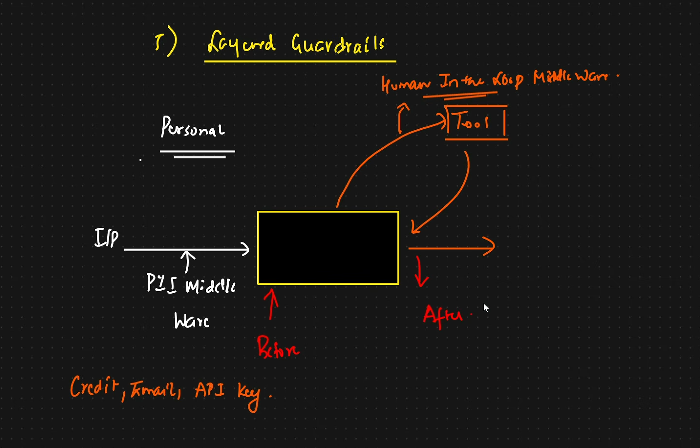

In [61]:
from langchain.agents import create_agent
from langchain.agents.middleware import PIIMiddleware, HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.tools import tool

@tool
def search_tool(query: str) -> str:
    """Search for information."""
    return f"Search results: {query}"

@tool
def send_email_tool(to: str, body: str) -> str:
    """Send an email."""
    return f"Email sent to {to}"

# Full layered guardrail stack
production_agent = create_agent(
    model="google_genai:gemini-3.5-flash-lite",
    tools=[search_tool, send_email_tool],
    middleware=[
        # Layer 1: Deterministic input filter (before agent)
        ContentFilterMiddleware(banned_keywords=["hack", "exploit", "malware"]),

        # Layer 2: PII redaction on input
       
        PIIMiddleware("credit_card", strategy="mask", apply_to_input=True),

        # Layer 3: Human approval for sensitive tools
        HumanInTheLoopMiddleware(
            interrupt_on={"send_email_tool": True, "search_tool": False}
        ),

        # Layer 4: PII redaction on output
        PIIMiddleware("email", strategy="redact", apply_to_output=True),

        # Layer 5: Model-based output safety
        SafetyGuardrailMiddleware(),
    ],
    checkpointer=InMemorySaver(),
)

print("🏭 Production-grade agent with 5-layer guardrails created!")

🏭 Production-grade agent with 5-layer guardrails created!


---
## 🏥 Section 8: Real-World Use Case — Healthcare Chatbot

A healthcare chatbot that:
1. **Blocks** off-topic or harmful requests
2. **Redacts** patient PII (emails, credit card numbers)
3. **Requires human approval** before booking appointments
4. **Validates** that outputs are medically appropriate

In [73]:
from typing import Any
from langchain.agents.middleware import AgentMiddleware, AgentState, hook_config
from langchain.agents.middleware import PIIMiddleware, HumanInTheLoopMiddleware
from langgraph.runtime import Runtime
from langchain.agents import create_agent
from langchain_core.tools import tool
from langgraph.checkpoint.memory import InMemorySaver
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import AIMessage

# --- Healthcare-specific content filter ---
class HealthcareSafetyFilter(AgentMiddleware):
    """Block non-medical or harmful requests in a healthcare context."""

    BLOCKED_TOPICS = ["drug synthesis", "self-harm", "suicide method", "weapon", "hack"]

    @hook_config(can_jump_to=["end"])
    def before_agent(self, state: AgentState, runtime: Runtime) -> dict[str, Any] | None:
        if not state["messages"]:
            return None

        first_msg = state["messages"][0]
        if first_msg.type != "human":
            return None

        content = first_msg.content
        for topic in self.BLOCKED_TOPICS:
            if topic in content:
                return {
                    "messages": [{
                        "role": "assistant",
                        "content": (
                            "I'm a healthcare assistant and can only help with "
                            "medical questions, appointments, and health information. "
                            "If you're in crisis, please call 112 or your local emergency number."
                        )
                    }],
                    "jump_to": "end"
                }
        return None


# --- Medical output validator ---
class MedicalOutputValidator(AgentMiddleware):
    """Ensure all responses include appropriate medical disclaimers."""

    DISCLAIMER = "\n\n⚕️ *This is general health information, not medical advice. Please consult a qualified healthcare professional.*"

    @hook_config(can_jump_to=["end"])
    def after_agent(self, state: AgentState, runtime: Runtime) -> dict[str, Any] | None:
        if not state["messages"]:
            return None

        last_message = state["messages"][-1]
        if not isinstance(last_message, AIMessage):
            return None

        # Add disclaimer if not already present
        if "medical advice" not in last_message.content:
            last_message.content += self.DISCLAIMER

        return None


# --- Healthcare tools ---
@tool
def search_symptoms(symptoms: str) -> str:
    """Search for information about medical symptoms."""
    return f"Symptom information for: {symptoms}. Please consult a doctor for diagnosis."

@tool
def book_appointment(patient_name: str, date: str, doctor: str) -> str:
    """Book a medical appointment."""
    return f"Appointment booked for {patient_name} with Dr. {doctor} on {date}"

@tool
def get_medication_info(medication: str) -> str:
    """Get information about a medication."""
    return f"General info about {medication}. Always follow your doctor's prescription."


# --- Build the healthcare chatbot ---
healthcare_bot = create_agent(
    model="google_genai:gemini-3.5-flash-lite",
    tools=[search_symptoms, book_appointment, get_medication_info],
    middleware=[
        # Guardrail 1: Block harmful/off-topic requests
        HealthcareSafetyFilter(),

        # Guardrail 2: Redact patient PII from inputs
        PIIMiddleware("email", strategy="redact", apply_to_input=True),
        PIIMiddleware("credit_card", strategy="mask", apply_to_input=True),

        # Guardrail 3: Require approval before booking appointments
        HumanInTheLoopMiddleware(
            interrupt_on={
                "book_appointment": True,
                "search_symptoms": False,
                "get_medication_info": False,
            }
        ),

        # Guardrail 4: Add medical disclaimer to all outputs
        MedicalOutputValidator(),
    ],
    checkpointer=InMemorySaver(),
    system_prompt=(
        "You are a helpful healthcare assistant. "
        "You can search for symptoms, medication information, and help book appointments. "
        "Always be empathetic and remind users to consult a doctor for diagnosis."
    )
)

print("🏥 Healthcare chatbot with full guardrail stack created!")

🏥 Healthcare chatbot with full guardrail stack created!


In [74]:
# Test 1: Safe medical query
config_t1 = {"configurable": {"thread_id": "healthcare_session_t1"}}

result = healthcare_bot.invoke(
    {"messages": [{"role": "user", "content": "What are symptoms of Type 2 Diabetes?"}]},
    config=config_t1
)

result
# print("✅ Safe medical query response:")
# print(result["messages"][-1].content)

{'messages': [HumanMessage(content='What are symptoms of Type 2 Diabetes?', additional_kwargs={}, response_metadata={}, id='94c769e5-981f-44e8-a096-b90fc7b36a47'),
  AIMessage(content=[], additional_kwargs={'function_call': {'name': 'search_symptoms', 'arguments': '{"symptoms": "Type 2 Diabetes"}'}, '__gemini_function_call_thought_signatures__': {'call_14251136552207566076': 'EmAKXgFpFH0Tp6KyhULpN0gMsv/URMIxnV8t7Ca094YaWg+NQPuAXnEUBmpjQu1O/uK4dZGW5TJtjvHbQUFnC8JThxC9Xcgh0c8xMUOYL4YJh62ykMCgHw5YX+uUOjBmOkU='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1d40d-526a-72d8-8893-f016fcfe408b-0', tool_calls=[{'name': 'search_symptoms', 'args': {'symptoms': 'Type 2 Diabetes'}, 'id': 'call_14251136552207566076', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 209, 'output_tokens': 21, 'total_tokens': 230, 'input_token_details': {'cache_read': 0}}),
  Tool

In [75]:
# Test 2: Query with PII (email gets redacted)
result = healthcare_bot.invoke({
    "messages": [{
        "role": "user",
        "content": "My email is patient123@gmail.com. What can I take for a headache?"
    }]},
    config=config_t1
)
print("=== PII Redaction Test ===")
print(result["messages"][-1].content)

=== PII Redaction Test ===
[{'type': 'text', 'text': "Common over-the-counter options for treating headaches include pain relievers such as acetaminophen, ibuprofen, or aspirin. \n\nHowever, before taking any medication, it's important to consider a few things:\n* Are you taking any other medications or do you have any underlying health conditions?\n* Is this a typical headache for you, or is it unusually severe or sudden?\n\nIf headaches are frequent, severe, or do not improve with over-the-counter options, you should consult a doctor. Would you like me to help you book an appointment with a healthcare provider? \n\n⚕️ *This information is for educational purposes and should not replace professional medical advice. Always consult a doctor or pharmacist before starting any new medication.*", 'extras': {'signature': 'EmAKXgFpFH0Tq9fNjLlSI75GHzcwswbfxtwbMa4uMT6TmLkWdYsQPVOfio9v8eHcvbPdw4Ot2jpOAj+I0yzM9mE48q/FAsJF0YQjMzB48eHAAQ0cYafbr/sxwS5o0xygBzo='}}, '\n', '\n', '⚕', '️', ' ', '*', 'T'

In [76]:
# Test 3: Off-topic / harmful request — gets blocked
result = healthcare_bot.invoke({
    "messages": [{"role": "user", "content": "How do I synthesize drugs at home?"}]
},
 config=config_t1)
print("=== Blocked Request ===")
print(result["messages"][-1].content)

=== Blocked Request ===
[{'type': 'text', 'text': "I cannot provide instructions on how to synthesize drugs at home. \n\nIf you are dealing with a medical condition or pain, I strongly encourage you to consult a qualified healthcare professional or pharmacist for safe, legal, and medically approved treatment options. \n\nIf you're looking for help with a specific health concern or symptoms, I'd be happy to help you find appropriate medical resources or assist in booking an appointment with a doctor"}, {'type': 'text', 'text': '.', 'extras': {'signature': 'EmAKXgFpFH0TU2vpFcYkspS3uaHw2QovodHiQycXjDh4tOd+rW7emmlUXQJYciuVN16ehs8o9S2rXCryGAoLVLVjowP+1hhdYxjxGBjN3FIGbpEjQd8Q5hFA9sxAvtplqjU='}}, '\n', '\n', '⚕', '️', ' ', '*', 'T', 'h', 'i', 's', ' ', 'i', 's', ' ', 'g', 'e', 'n', 'e', 'r', 'a', 'l', ' ', 'h', 'e', 'a', 'l', 't', 'h', ' ', 'i', 'n', 'f', 'o', 'r', 'm', 'a', 't', 'i', 'o', 'n', ',', ' ', 'n', 'o', 't', ' ', 'm', 'e', 'd', 'i', 'c', 'a', 'l', ' ', 'a', 'd', 'v', 'i', 'c', 'e',

In [77]:
# Test 4: Appointment booking — requires human approval
config = {"configurable": {"thread_id": "healthcare_session_001"}}

result = healthcare_bot.invoke(
    {"messages": [{"role": "user", "content": "Book me an appointment with Dr. Sharma on March 15"}]},
    config=config
)
print("=== Appointment Booking — Awaiting Approval ===")
print(result)

# Approve
from langgraph.types import Command
approved = healthcare_bot.invoke(
    Command(resume={"decisions": [{"type": "approve"}]}),
    config=config
)
print("\n=== After Approval ===")
print(approved["messages"][-1].content)

=== Appointment Booking — Awaiting Approval ===
{'messages': [HumanMessage(content='Book me an appointment with Dr. Sharma on March 15', additional_kwargs={}, response_metadata={}, id='197fea1b-0b4b-4dac-9244-d2862b21d15c'), AIMessage(content=[], additional_kwargs={'function_call': {'name': 'book_appointment', 'arguments': '{"date": "March 15", "doctor": "Dr. Sharma", "patient_name": "[Patient]"}'}, '__gemini_function_call_thought_signatures__': {'call_18355629874142306051': 'EmAKXgFpFH0Tp1p6ayPRuGkFS8uOvT7zyiI+270a/XSvcfEmOqvLEHnj7Wg+lmFf3N/2GZZabk1JREi1uyYVtol6oiF088CmkFKK0qAY3pOXg56RNftL/2SWFmxtTcrJW7I='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1d40d-dcf9-742c-987d-cdf03bac68a5-0', tool_calls=[{'name': 'book_appointment', 'args': {'date': 'March 15', 'doctor': 'Dr. Sharma', 'patient_name': '[Patient]'}, 'id': 'call_18355629874142306051', 'type': 'tool_call'}], invalid

---
## 📝 Summary

| Guardrail Type | Hook | When it Runs | Best For |
|---|---|---|---|
| PII Middleware | Input/Output | Around model calls | Data privacy, compliance |
| Human-in-the-Loop | Tool level | Before sensitive tools | High-stakes decisions |
| Content Filter | `before_agent` | Start of invocation | Blocking bad inputs early |
| Safety Validator | `after_agent` | End of invocation | Output quality/safety |
| Custom Logic | Any hook | Anywhere | Any business rule |

### 🔑 Key Takeaways
1. **Guardrails = Middleware** — implement them via the `middleware=[]` parameter in `create_agent()`
2. **Layer your guardrails** — defense in depth is best practice
3. **Deterministic first, model-based second** — use cheap rule-based checks early to avoid expensive LLM calls
4. **Human-in-the-Loop requires a checkpointer** — use `InMemorySaver` for dev, persistent store for production
5. **Custom middleware** gives you full control via `before_agent()` and `after_agent()` hooks

---
### 📚 Additional Resources
- [LangChain Guardrails Docs](https://docs.langchain.com/oss/python/langchain/guardrails)
- [Middleware Docs](https://docs.langchain.com/oss/python/langchain/middleware/overview)
- [Human-in-the-Loop Docs](https://docs.langchain.com/oss/python/langchain/human-in-the-loop)
- [LangSmith for Observability](https://docs.langchain.com/oss/python/langchain/observability)

